# 05 · Random forest (ensemble track)

Predict `log_price` with sklearn `RandomForestRegressor` on the shared `strfair` features
([`docs/models.md`](../docs/models.md), [`docs/pipeline.md`](../docs/pipeline.md)).

Same rules as the other model notebooks:
- start from `strfair.prepare(city, snapshot)`
- never use `strfair.LEAKY` or `strfair.DEMAND_RESPONSE` as inputs
- report MAE/RMSE on log price and MAE in dollars; slice by quote type and room type

Before the first run (from the repo root):

```bash
python scripts/download_data.py toronto@2026-06-15
```

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="Pandas requires version")
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "strfair").is_dir())))
import strfair

CITY = "toronto"           # one of strfair.PINNED_SNAPSHOTS
SNAPSHOT = "2026-06-15"    # team's date for that city (required: there is no "latest")

In [3]:
data = strfair.prepare(CITY, SNAPSHOT)   # compare the `data` hash with a teammate

toronto 2026-06-15 | listings 22,198 rows, 18,262 in sample | features 110 cols | code f4f6a29c | data 597d7dbb  (cached)


## Feature matrix

Drop leaky targets / revenue columns and demand-response columns (availability, recent review
velocity). Keep raw lat/lon for the ensemble. RF does not need scaling; median-impute numerics
and one-hot encode categoricals inside the pipeline.

In [4]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

F = data.features.copy()

drop = (
    list(strfair.LEAKY)
    + list(strfair.DEMAND_RESPONSE)
    + list(strfair.ID_COLUMNS)
    + ["neighbourhood_raw"]  # unpooled copy of neighbourhood; use pooled `neighbourhood`
)
X_cols = [c for c in F.columns if c not in drop]
cat = list(F[X_cols].select_dtypes(exclude="number").columns)
num = [c for c in X_cols if c not in cat]

y = F["log_price"]
X = F[X_cols]

print(f"{len(X_cols)} inputs ({len(num)} numeric, {len(cat)} categorical) | n={len(F):,}")
print("categoricals:", cat)

84 inputs (78 numeric, 6 categorical) | n=18,262
categoricals: ['lead_band', 'min_nights_band', 'room_type', 'room', 'property_group', 'neighbourhood']


## Model + 5-fold out-of-fold predictions

Identical frames + `KFold(5, shuffle=True, random_state=42)` → same folds as teammates
(`docs/pipeline.md`). Modest depth / enough trees per `docs/models.md`.

In [5]:
pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat),
])

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=5,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42,
)

model = make_pipeline(pre, rf)
cv = KFold(5, shuffle=True, random_state=42)

oof = cross_val_predict(model, X, y, cv=cv, n_jobs=-1)

rmse = mean_squared_error(y, oof) ** 0.5
mae_log = mean_absolute_error(y, oof)
mae_usd = mean_absolute_error(F["price"], np.exp(oof))

print(f"5-fold OOF  RMSE(log)={rmse:.3f}  MAE(log)={mae_log:.3f}  MAE($)=${mae_usd:,.0f}")

F = F.assign(
    fair_log_price=oof,
    fair_price=np.exp(oof),
    residual=y - oof,
)
F[["id", "price", "fair_price", "log_price", "fair_log_price", "residual"]].head()

5-fold OOF  RMSE(log)=0.390  MAE(log)=0.270  MAE($)=$88


,id,price,fair_price,log_price,fair_log_price,residual
0,27423,16.90,55.776862,2.827314,4.021359,-1.194045
1,44452,99.85,109.513554,4.603669,4.696048,-0.092379
2,44469,76.70,73.960737,4.339902,4.303534,0.036367
3,45399,107.41,153.611026,4.676653,5.034424,-0.357770
4,45893,71.86,66.966222,4.274720,4.204188,0.070531


## Error slices

Report by monthly vs nightly quote and by room type (`docs/models.md` §3).

In [7]:
def slice_mae(frame: pd.DataFrame, by: str) -> pd.DataFrame:
    rows = []
    for key, g in frame.groupby(by, dropna=False):
        rows.append({
            by: key,
            "n": len(g),
            "mae_log": mean_absolute_error(g["log_price"], g["fair_log_price"]),
            "mae_usd": mean_absolute_error(g["price"], g["fair_price"]),
        })
    return pd.DataFrame(rows).sort_values("n", ascending=False)

if "is_monthly_quote" in F.columns:
    display(slice_mae(F.assign(quote=np.where(F["is_monthly_quote"] >= 0.5, "monthly", "nightly")), "quote"))

if "room_type" in F.columns:
    display(slice_mae(F, "room_type"))

,quote,n,mae_log,mae_usd
0,monthly,9773,0.288218,71.154236
1,nightly,8489,0.248089,107.363651


,room_type,n,mae_log,mae_usd
0,Entire home/apt,12491,0.276281,108.586092
2,Private room,5694,0.254210,42.523276
1,Hotel room,56,0.254642,133.459447
3,Shared room,21,0.477602,40.487789


## Fit on all data + feature importances

Refit once on the full sample for a host-facing importance view. Importances are impurity-based
(how much MSE each feature reduced across trees), not causal effects.

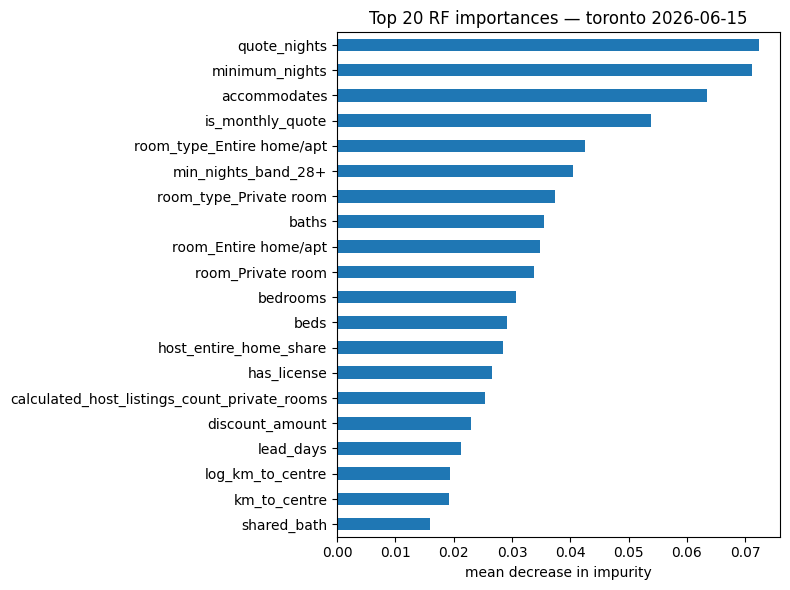

,importance
quote_nights,0.072356
minimum_nights,0.071213
accommodates,0.063423
is_monthly_quote,0.053865
room_type_Entire home/apt,0.042442
min_nights_band_28+,0.040406
room_type_Private room,0.037339
baths,0.035538
room_Entire home/apt,0.034862
room_Private room,0.033850


In [8]:
import matplotlib.pyplot as plt

model.fit(X, y)

ohe = model.named_steps["columntransformer"].named_transformers_["cat"]
cat_names = list(ohe.get_feature_names_out(cat))
feat_names = list(num) + cat_names

importances = pd.Series(
    model.named_steps["randomforestregressor"].feature_importances_,
    index=feat_names,
).sort_values(ascending=False)

top = importances.head(20)
ax = top.iloc[::-1].plot(kind="barh", figsize=(8, 6), title=f"Top 20 RF importances — {CITY} {SNAPSHOT}")
ax.set_xlabel("mean decrease in impurity")
plt.tight_layout()
plt.show()

importances.head(20).to_frame("importance")

## Optional next steps

- Change `CITY` / `SNAPSHOT` to another pinned city and compare MAE.
- Stability check: rerun on `strfair.STABILITY_SNAPSHOTS[CITY]` (Mar 2026) where available.
- Validation only: under-priced listings (`residual = log_price - fair_log_price < 0`) should tend to show stronger demand proxies (`availability_*`, recent reviews) — do not train on those columns.
- Compare OOF MAE here to the ElasticNet sketch in `00_prepare_template.ipynb`.